# 01 · Calibrating an agent-based market model by Simulated Method of Moments

**Question.** Given only a return series, can we recover the behavioural parameters of an agent-based model (ABM) in which prices emerge from the interaction of *fundamentalists* and *chartists*? And which optimiser should we trust when the objective function itself is random?

**Setting.** Identifiability study on synthetic data: we simulate the model at known parameters, then try to recover them. If calibration fails here, it cannot be trusted on real data.

| | |
|---|---|
| **Model** | Modified Chiarella model: the fundamental value is an EMA of past prices, not an exogenous process |
| **Estimator** | Simulated Method of Moments (SMM/GMM, Hansen 1982) on 6 stylised facts, iterative optimal weighting |
| **Benchmarks** | 8 `scipy.optimize` methods and differential evolution, 10 random starts each |
| **Uncertainty** | 100 independent re-estimations → bias / std / RMSE per parameter (sloppiness) |
| **Alternatives tested** | Random-forest and XGBoost surrogates, surrogate-assisted ABC, deterministic trajectory fitting |
| **Stack** | NumPy · Numba (JIT) · SciPy · joblib · scikit-learn · XGBoost |

**Contents.** 1 Model · 2 Moments · 3 Market regimes · 4 GMM distance · 5 Optimiser benchmark · 6 Optimal GMM · 7 Sloppiness over 100 runs · 8 Loss landscape · 9 Surrogates & S-ABC · 10 Why trajectory fitting fails · 11 Conclusions

In [1]:
import sys, time, warnings
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
import matplotlib.gridspec as gridspec
from numba import njit
from scipy.optimize import minimize
from scipy.stats import gaussian_kde
from joblib import Parallel, delayed

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(ROOT / "src"))
FIG = ROOT / "figures"; FIG.mkdir(exist_ok=True)

from abm import chiarella_model, compute_moments, PARAM_NAMES, MOMENT_NAMES
from abm import gmm
from abm.plotting import (style_ax, new_fig, DARK, CARD, BLUE, TEAL, CORAL,
                          AMBER, VIOLET, LGRAY, WHITE, GRID)

warnings.filterwarnings("ignore")
def save(fig, name):
    fig.savefig(FIG / name, dpi=110, bbox_inches="tight", facecolor=fig.get_facecolor())

## 1 · The model

Log-price $p_t$, trend memory $m_t$, fundamental value $v_t$:

$$p_{t+1} - p_t = \underbrace{\kappa\bigl[(v_t - p_t)^3 - (v_{t-1} - p_{t-1})^3\bigr]}_{\text{fundamentalists}} + \underbrace{\beta\bigl[\tanh(\gamma m_t) - \tanh(\gamma m_{t-1})\bigr]}_{\text{chartists}} + \sigma_N\,\eta_t,\qquad \eta_t \sim \mathcal N(0,1)$$

$$m_t = (1-\alpha)\,m_{t-1} + \alpha\,(p_t - p_{t-1}), \qquad \boxed{v_t = (1-\lambda)\,v_{t-1} + \lambda\,p_t}$$

| Parameter | Role |
|---|---|
| $\kappa$ | fundamentalist restoring force (cubic: reacts strongly to large mispricings) |
| $\beta$ | strength of the chartist (trend-following) demand |
| $\gamma$ | saturation of the trend signal through $\tanh$ |
| $\alpha$ | forgetting rate of the trend memory |
| $\lambda$ | adaptation speed of the perceived fundamental value |
| $\sigma_N$ | exogenous noise |

The recursion is non-linear, so it cannot be vectorised. It is compiled with Numba (`src/abm/chiarella.py`). Shocks $\eta$ are passed in as an argument, which makes it possible to reuse the same draws across parameter values (*common random numbers*, tested in §4).

In [2]:
# Trigger JIT compilation once
t0 = time.time()
_p, _r = chiarella_model(np.random.normal(0, 1, 200), 0.05, 0.1, 1.0, 0.1, 0.05, 0.01)
compute_moments(_r)
print(f"Numba compilation / cache load: {time.time() - t0:.2f}s")

t0 = time.time()
for _ in range(1000):
    chiarella_model(np.random.normal(0, 1, 1500), 0.05, 0.1, 1.0, 0.1, 0.05, 0.01)
print(f"1,000 simulated paths of length 1,500: {time.time() - t0:.2f}s")

Numba compilation / cache load: 0.23s
1,000 simulated paths of length 1,500: 0.05s


## 2 · Target moments

GMM needs at least as many moments as parameters. We use six cheap moments that summarise the usual stylised facts of returns (`src/abm/moments.py`, re-implemented for Numba):

| # | Moment | Stylised fact |
|---|---|---|
| 1 | Variance of $r$ | volatility level |
| 2 | Excess kurtosis | fat tails |
| 3 | 99% quantile of $\lvert r\rvert$ | size of extreme moves |
| 4 | ACF of $r$ at lag 1 | absence of linear predictability |
| 5 | ACF of $r^2$ at lag 1 | volatility clustering |
| 6 | Skewness | asymmetry |

## 3 · Three market regimes

Before calibrating, we look at what the parameters *do*. Three configurations differ only in the balance between $\kappa$ and $\beta$.

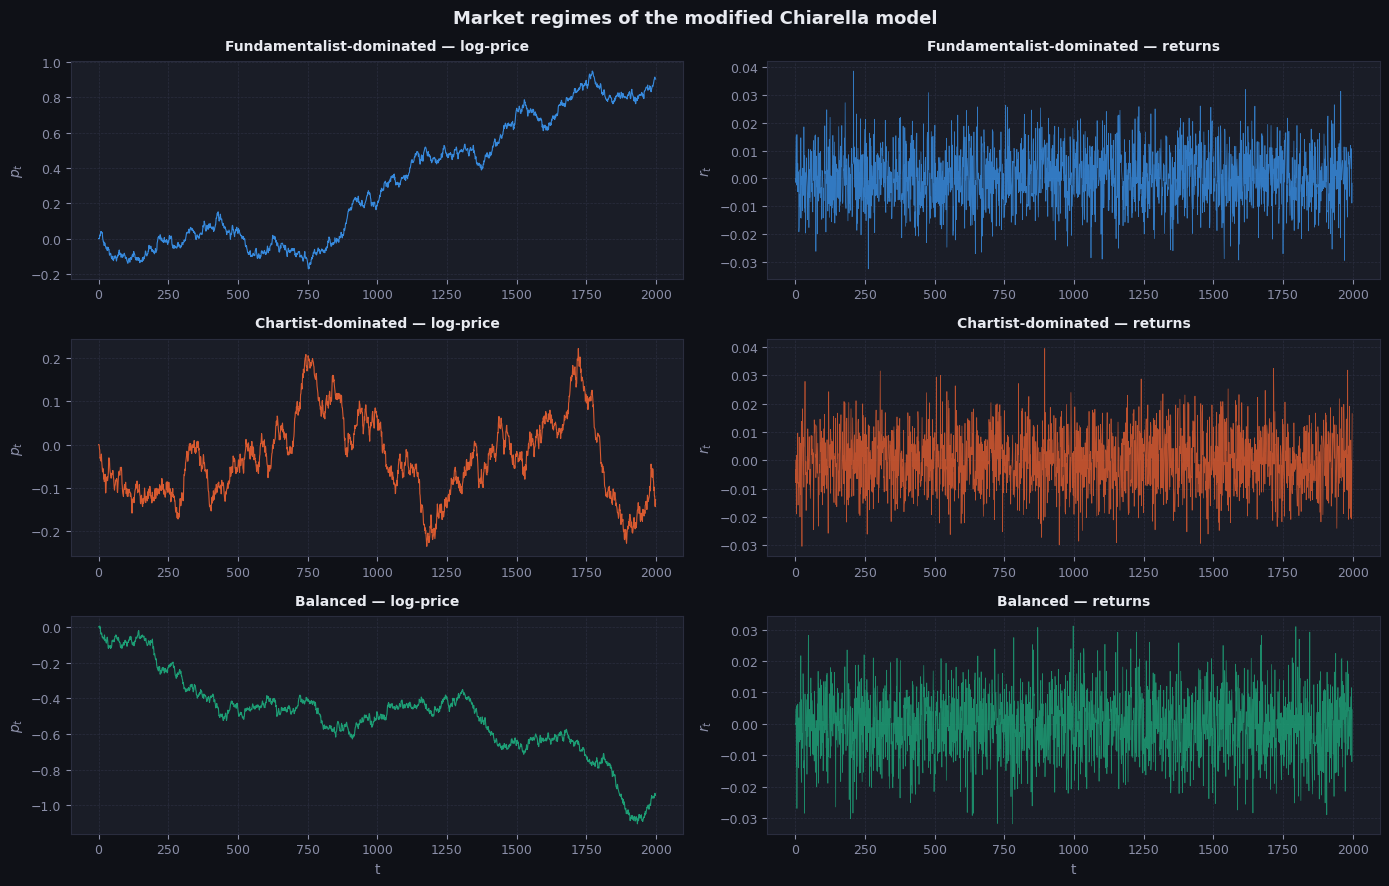

In [3]:
NIT = 2000
regimes = {
    "Fundamentalist-dominated": np.array([0.20, 0.05, 1.0, 0.10, 0.05, 0.01]),
    "Chartist-dominated":       np.array([0.01, 0.20, 1.0, 0.10, 0.05, 0.01]),
    "Balanced":                 np.array([0.05, 0.10, 1.0, 0.10, 0.05, 0.01]),
}
regime_colors = dict(zip(regimes, [BLUE, CORAL, TEAL]))

np.random.seed(42)
fig, axes = new_fig(3, 2, figsize=(14, 9))
for i, (name, xi) in enumerate(regimes.items()):
    p, r = chiarella_model(np.random.normal(0, 1, NIT), *xi)
    axes[i, 0].plot(p, color=regime_colors[name], lw=0.8)
    style_ax(axes[i, 0], f"{name} — log-price"); axes[i, 0].set_ylabel("$p_t$")
    axes[i, 1].plot(r, color=regime_colors[name], lw=0.5, alpha=0.85)
    style_ax(axes[i, 1], f"{name} — returns"); axes[i, 1].set_ylabel("$r_t$")
axes[2, 0].set_xlabel("t"); axes[2, 1].set_xlabel("t")
fig.suptitle("Market regimes of the modified Chiarella model", color=WHITE,
             fontsize=13, fontweight="bold")
plt.tight_layout(); save(fig, "01_regimes.png"); plt.show()

In [4]:
# Moment signature of each regime, averaged over 200 paths (with ± std across paths)
rng = np.random.default_rng(0)
print(f"{'Regime':<26}" + "".join(f"{m:>16}" for m in MOMENT_NAMES))
print("-" * 122)
for name, xi in regimes.items():
    M = np.array([compute_moments(chiarella_model(rng.normal(0, 1, NIT), *xi)[1])
                  for _ in range(200)])
    mu, sd = M.mean(0), M.std(0)
    print(f"{name:<26}" + "".join(f"{a:>9.4f}±{b:<6.4f}" for a, b in zip(mu, sd)))

Regime                                 Var        Kurtosis          Q99|r|          ACF(r)         ACF(r²)            Skew
--------------------------------------------------------------------------------------------------------------------------
Fundamentalist-dominated     0.0001±0.0000  -0.0020±0.1030   0.0257±0.0008   0.0018±0.0213  -0.0003±0.0230  -0.0048±0.0532
Chartist-dominated           0.0001±0.0000   0.0018±0.1042   0.0257±0.0007   0.0196±0.0232   0.0006±0.0230   0.0002±0.0595
Balanced                     0.0001±0.0000   0.0087±0.1182   0.0257±0.0008   0.0093±0.0230   0.0012±0.0229   0.0077±0.0540


The moment signatures are almost identical. To see why, we measure the average size of each of the three terms that drive $p_{t+1} - p_t$ along a simulated path.

In [5]:
def term_sizes(xi, T=2000, seed=0):
    k, b, g, a, l, s = xi
    eta = np.random.default_rng(seed).normal(0, 1, T)
    v = np.zeros(T); m = np.zeros(T); p = np.zeros(T); F, C, N, gap = [], [], [], []
    for t in range(1, T - 1):
        v[t] = (1 - l) * v[t-1] + l * p[t]; m[t] = (1 - a) * m[t-1] + a * (p[t] - p[t-1])
        f = k * ((v[t]-p[t])**3 - (v[t-1]-p[t-1])**3); c = b * (np.tanh(g*m[t]) - np.tanh(g*m[t-1]))
        n = s * eta[t]; p[t+1] = p[t] + f + c + n
        F.append(abs(f)); C.append(abs(c)); N.append(abs(n)); gap.append(abs(v[t] - p[t]))
    return np.mean(F), np.mean(C), np.mean(N), np.mean(gap)

TRUE_BENCH = regimes["Fundamentalist-dominated"].copy(); TRUE_BENCH[5] = 0.02
print(f"{'Configuration':<36}{'|fundamentalist|':>17}{'|chartist|':>12}{'|noise|':>10}{'noise/agents':>14}{'|v - p|':>10}")
for name, xi in list(regimes.items()) + [("Calibration target (sigma_N = 0.02)", TRUE_BENCH)]:
    f, c, n, gap = term_sizes(xi)
    print(f"{name:<36}{f:>17.1e}{c:>12.1e}{n:>10.1e}{n / (f + c):>13.0f}x{gap:>10.3f}")

Configuration                        |fundamentalist|  |chartist|   |noise|  noise/agents   |v - p|
Fundamentalist-dominated                      4.4e-06     4.1e-05   8.0e-03          177x     0.026
Chartist-dominated                            2.2e-07     1.6e-04   8.0e-03           49x     0.026
Balanced                                      1.1e-06     8.2e-05   8.0e-03           97x     0.026
Calibration target (sigma_N = 0.02)           3.5e-05     8.2e-05   1.6e-02          137x     0.052


### Reading the regimes

The price paths look different, but the **return moments of the three regimes are statistically indistinguishable**: every difference is well inside one standard deviation across paths. The only moment that moves at all is the lag-1 ACF of returns (0.002 → 0.020 from fundamentalist- to chartist-dominated), and even that shift is smaller than its own sampling noise (±0.02).

The term-size table explains it. With $\sigma_N = 0.01$ the typical mispricing $|v_t - p_t|$ is about 0.03, so the cubic fundamentalist term is of order $\kappa \cdot 0.03^3 \approx 10^{-6}$, and the chartist term $\beta\,\Delta\tanh(\gamma m_t)$ is of order $10^{-4}$. **The noise is 50 to 180 times larger than both behavioural terms combined.** At these parameter values the model is, to first order, a Gaussian random walk with a weak lag-1 autocorrelation.

This sets expectations for everything that follows: only $\sigma_N$ has a strong footprint in the moments; the chartist block ($\beta, \gamma, \alpha$) leaves a faint trace in ACF(r), and $\kappa$ and $\lambda$ leave almost none.

## 4 · The GMM distance

Because the model is stochastic, model moments are estimated by simulation (hence *Simulated* Method of Moments). For a candidate $\xi$ we simulate `N_SIM = 6` paths of length 1,500 and average their moments:

$$D_W(\xi) = d(\xi)^\top W\, d(\xi), \qquad d_k(\xi) = \frac{\bar c_{k}^{\,\text{sim}}(\xi) - c_{k}^{\,\text{target}}}{s_k}$$

The moments live on very different scales (variance ~$10^{-4}$, kurtosis ~1), so each gap is divided by $s_k$, the inter-simulation std of moment $k$ at the target. All moments then contribute on an $O(1)$ scale.

**Target.** The fundamentalist-dominated regime with $\sigma_N$ raised to 0.02, so that the volatility level carries more information.

**The loss is noisy.** In the main study, fresh shocks are drawn at every evaluation, so two calls at the same $\xi$ return different values. The cell below measures this and compares with common random numbers (the same shocks reused at every call).

In [6]:
TRUE = regimes["Fundamentalist-dominated"].copy()
TRUE[5] = 0.02
MOM_TARGET, MOM_SCALE = gmm.target_scale(TRUE)
distance = gmm.make_distance(MOM_TARGET, MOM_SCALE)
W0 = np.eye(6)

print("True parameters:", dict(zip(PARAM_NAMES, TRUE.round(4))))
print("Target moments :", dict(zip(MOMENT_NAMES, MOM_TARGET.round(5))))

# How noisy is D_W? 200 evaluations at the same point, with and without CRN
np.random.seed(0)
x_test = TRUE * np.array([1.3, 1.5, 0.8, 1.2, 1.5, 1.0])
fresh = np.array([distance(x_test, W0) for _ in range(200)])
crn_vals = np.array([gmm.make_distance(MOM_TARGET, MOM_SCALE, crn_seed=s)(x_test, W0)
                     for s in range(200)])
crn_fixed = gmm.make_distance(MOM_TARGET, MOM_SCALE, crn_seed=0)
print(f"\nD_W at a fixed point, fresh shocks : mean {fresh.mean():.2f}, std {fresh.std():.2f} "
      f"(coefficient of variation {fresh.std()/fresh.mean():.0%})")
print(f"Same point, CRN (seed 0), 2 calls   : {crn_fixed(x_test, W0):.4f}, {crn_fixed(x_test, W0):.4f}  -> deterministic")

True parameters: {'kappa': np.float64(0.2), 'beta': np.float64(0.05), 'gamma': np.float64(1.0), 'alpha': np.float64(0.1), 'lmbda': np.float64(0.05), 'sigma_N': np.float64(0.02)}
Target moments : {'Var': np.float64(0.0004), 'Kurtosis': np.float64(-0.00256), 'Q99|r|': np.float64(0.0514), 'ACF(r)': np.float64(0.00086), 'ACF(r²)': np.float64(-0.00067), 'Skew': np.float64(-0.00263)}



D_W at a fixed point, fresh shocks : mean 1.11, std 0.69 (coefficient of variation 62%)
Same point, CRN (seed 0), 2 calls   : 1.1397, 1.1397  -> deterministic


## 5 · Which optimiser? A benchmark on a noisy objective

Five families are possible in `scipy.optimize`:

| Family | Methods | Needs |
|---|---|---|
| Derivative-free | Nelder-Mead, Powell, COBYLA, COBYQA | nothing |
| Gradient (finite differences) + bounds | L-BFGS-B, TNC, SLSQP, trust-constr | numerical gradient |
| Newton-type | Newton-CG, dogleg, trust-ncg/krylov/exact | analytical Jacobian → excluded, $D_W$ has none |
| Global | differential evolution | population of candidates |

Finite-difference gradients are computed with steps of ~$10^{-8}$, far below the noise level of $D_W$, so they are essentially random. A quick check:

In [7]:
np.random.seed(1)
x0_demo = gmm.LO + 0.5 * (gmm.HI - gmm.LO)
for mth in ["CG", "BFGS"]:
    res = minimize(distance, x0_demo, args=(W0,), method=mth, options={"maxiter": 60})
    print(f"{mth:6s} success={res.success}  fun={res.fun:.4g}")

CG     success=False  fun=2.38e+04


BFGS   success=False  fun=2.317e+04


**Protocol.** Each method is started from the same 10 random points. We record the convergence rate (`success` flag), the best and median final loss, and the run time. Selection rule, fixed *before* looking at results: **convergence rate first, then median loss**.

In [8]:
np.random.seed(2)
BENCH_METHODS = gmm.METHODS_FREE + gmm.METHODS_BOUNDED
bench = {}
print(f"{'Method':<15}{'conv':>6}{'best loss':>12}{'median loss':>13}{'time':>8}")
print("-" * 54)
for mth in BENCH_METHODS:
    bench[mth] = gmm.run_multistart(mth, distance, W0)
    b = bench[mth]
    print(f"{mth:<15}{b['conv']:>6.0%}{b['best']:>12.3g}{b['med']:>13.3g}{b['time']:>7.1f}s")
bench["diff-evolution"] = gmm.run_differential_evolution(distance, W0)
b = bench["diff-evolution"]
print(f"{'diff-evolution':<15}{b['conv']:>6.0%}{b['best']:>12.3g}{b['med']:>13.3g}{b['time']:>7.1f}s")

Method           conv   best loss  median loss    time
------------------------------------------------------


Nelder-Mead        0%       0.038        0.501    4.5s


Powell            60%        0.26         1.28    1.6s


COBYLA           100%         1.2     1.61e+03    0.7s


COBYQA           100%      0.0664     1.62e+03    1.7s


L-BFGS-B          80%         157     6.49e+03    1.4s


TNC               60%         166     2.62e+04    1.5s
SLSQP              0%         193     2.66e+04    0.1s


trust-constr      20%        8.34     1.53e+03   15.0s


diff-evolution     0%      0.0171        0.126    7.9s


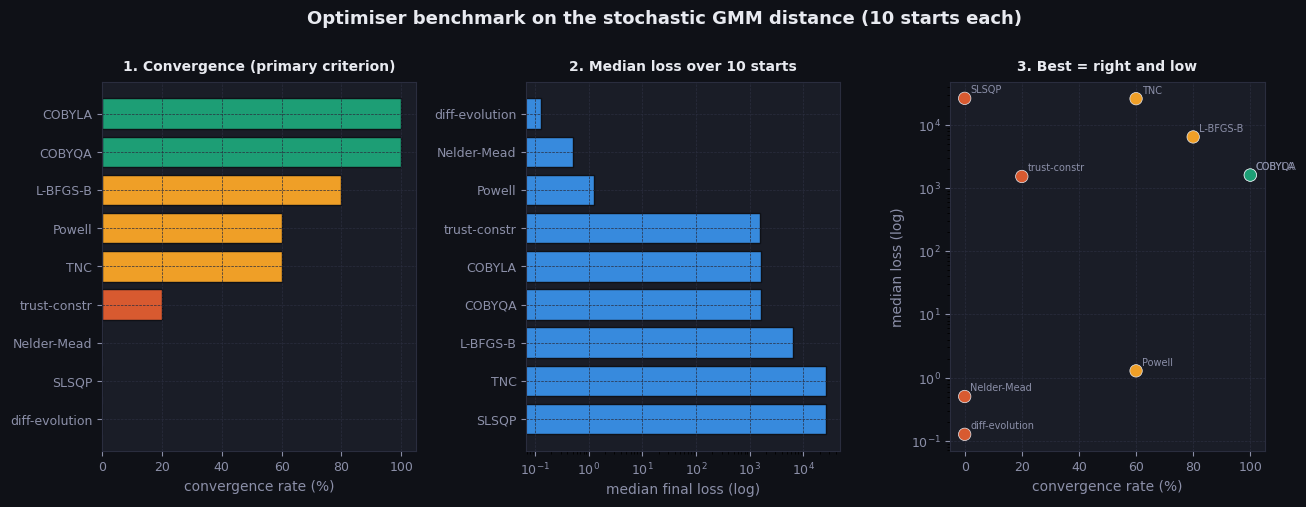

Highest convergence rate: 100% -> finalists ['COBYLA', 'COBYQA']
Selected by the rule (convergence, then median loss): COBYLA


In [9]:
names = list(bench)
convs = np.array([bench[m]["conv"] * 100 for m in names])
bests = np.array([bench[m]["best"] for m in names])
meds = np.array([bench[m]["med"] for m in names])
col = lambda c: TEAL if c >= 99 else (AMBER if c >= 50 else CORAL)

fig = plt.figure(figsize=(15, 4.8)); fig.patch.set_facecolor(DARK)
gs_ = gridspec.GridSpec(1, 3, figure=fig, wspace=0.35)
ax1 = fig.add_subplot(gs_[0]); o = np.argsort(-convs)
ax1.barh(range(len(names)), convs[o], color=[col(convs[i]) for i in o], edgecolor=DARK)
ax1.set_yticks(range(len(names))); ax1.set_yticklabels([names[i] for i in o], fontsize=8)
ax1.invert_yaxis(); ax1.set_xlabel("convergence rate (%)"); style_ax(ax1, "1. Convergence (primary criterion)")
ax2 = fig.add_subplot(gs_[1]); o = np.argsort(meds)
ax2.barh(range(len(names)), meds[o], color=BLUE, edgecolor=DARK)
ax2.set_yticks(range(len(names))); ax2.set_yticklabels([names[i] for i in o], fontsize=8)
ax2.set_xscale("log"); ax2.invert_yaxis(); ax2.set_xlabel("median final loss (log)"); style_ax(ax2, "2. Median loss over 10 starts")
ax3 = fig.add_subplot(gs_[2])
ax3.scatter(convs, meds, s=80, c=[col(c) for c in convs], edgecolor=WHITE, lw=0.5, zorder=3)
for i, n in enumerate(names):
    ax3.annotate(n, (convs[i], meds[i]), fontsize=7, color=LGRAY, xytext=(4, 4), textcoords="offset points")
ax3.set_yscale("log"); ax3.set_xlabel("convergence rate (%)"); ax3.set_ylabel("median loss (log)")
style_ax(ax3, "3. Best = right and low")
fig.suptitle("Optimiser benchmark on the stochastic GMM distance (10 starts each)",
             color=WHITE, fontsize=13, fontweight="bold", y=1.03)
save(fig, "01_optimizer_benchmark.png"); plt.show()

winner, max_conv, finalists = gmm.select_method(bench)
print(f"Highest convergence rate: {max_conv:.0%} -> finalists {list(finalists)}")
print(f"Selected by the rule (convergence, then median loss): {winner}")

### Reading the benchmark

- **Finite-difference gradient methods fail**, as expected on a function whose noise (coefficient of variation ≈ 60%) dwarfs the finite-difference step: CG and BFGS do not converge, and L-BFGS-B, TNC and SLSQP end at median losses in the thousands.
- **COBYLA and COBYQA are the only methods that report convergence on every start**, and the pre-registered rule therefore keeps them as finalists. Their median losses are tied (1.61e3 vs 1.62e3, a gap well inside the noise), and COBYQA reaches a far lower best loss (0.07 vs 1.2). We keep **COBYQA** for the rest of the study.
- **The `success` flag turns out to be a poor criterion.** A converged COBYQA run means "trust region shrank below tolerance", not "found a good minimum": half of the COBYQA starts stop at losses above 1,000. Conversely, **Nelder-Mead and differential evolution have the lowest median losses (0.50 and 0.13)** but report `success=False` only because they exhaust their iteration budget.

*In hindsight:* with a noisy objective, the right selection rule is the distribution of the final loss **re-evaluated with fresh simulations**, not the optimiser's own stopping flag. Differential evolution would be the better default, and §7 shows that the choice barely matters for identification anyway.

In [10]:
SELECTED_METHOD = "COBYQA"

## 6 · Iterative optimal GMM

Hansen (1982): the GMM estimator is efficient when $W = V^{-1}$, with $V$ the covariance of the moments at the optimum. $V$ depends on the unknown $\xi^\*$, so we iterate:

1. $W^{(0)} = I$;
2. $\xi^{(n)} = \arg\min D_{W^{(n)}}$ (COBYQA, 5 random starts);
3. simulate 60 paths at $\xi^{(n)}$, estimate $V$ on the normalised moments, set $W^{(n+1)} = \operatorname{pinv}(V + 10^{-6} I)$;
4. stop when $\lVert \xi^{(n)} - \xi^{(n-1)} \rVert < 10^{-5}$ or after 4 iterations.

In [11]:
np.random.seed(3)
xi_hat, loss_hat, ok_hat, W_opt, hist = gmm.gmm_optimal(MOM_TARGET, MOM_SCALE,
                                                        method=SELECTED_METHOD, seed=0)
print(f"{SELECTED_METHOD} | iterations: {len(hist)} | success: {ok_hat} | final loss: {loss_hat:.3e}\n")
print(f"{'param':<9}{'true':>9}{'estimate':>10}{'error':>10}")
for j, nm in enumerate(PARAM_NAMES):
    print(f"{nm:<9}{TRUE[j]:>9.4f}{xi_hat[j]:>10.4f}{xi_hat[j] - TRUE[j]:>+10.4f}")

COBYQA | iterations: 4 | success: True | final loss: 5.926e-01

param         true  estimate     error
kappa       0.2000    0.2749   +0.0749
beta        0.0500    0.5000   +0.4500
gamma       1.0000    0.4002   -0.5998
alpha       0.1000    0.2307   +0.1307
lmbda       0.0500    0.0204   -0.0296
sigma_N     0.0200    0.0197   -0.0003


One estimation already shows the pattern: $\sigma_N$ is recovered within 2%, while $\beta$ ends up on its upper bound (0.50 vs 0.05) and $\gamma$ is off by 60%. A single run cannot say whether this is bad luck or a structural problem, which is the purpose of the next section.

## 7 · 100 independent estimations: bias, dispersion and sloppiness

A single estimate says little about an estimator. We draw **100 new target paths** at the same true $\xi^\*$ (length 1,500 each, as a real calibration sample would be) and re-run the optimal GMM on each, in parallel with `joblib`. To keep the cost reasonable each run uses 2 GMM iterations, 3 starts and 40 covariance paths.

The spread of the 100 estimates is the sampling distribution of the estimator. A parameter is **stiff** if it is pinned down by the moments and **sloppy** if many values fit equally well.

In [12]:
N_MC = 100

def one_mc(seed):
    np.random.seed(seed)                       # seeds the noisy distance inside each worker
    rng = np.random.default_rng(seed)
    _p, r_t = chiarella_model(rng.normal(0, 1, gmm.NIT_SIM), *TRUE)
    xi, loss, ok, _W, _h = gmm.gmm_optimal(compute_moments(r_t), MOM_SCALE, method=SELECTED_METHOD,
                                           n_iter=2, n_start=3, n_cov=40, seed=seed + 10_000)
    return xi, loss, ok

t0 = time.time()
out = Parallel(n_jobs=-1)(delayed(one_mc)(s) for s in range(N_MC))
estimates = np.array([o[0] for o in out]); losses = np.array([o[1] for o in out])
converged = np.array([o[2] for o in out])
print(f"{N_MC} GMM runs in {time.time() - t0:.0f}s | optimiser success: {converged.mean():.0%}\n")

print(f"{'param':<9}{'true':>8}{'mean':>9}{'bias':>9}{'std':>8}{'RMSE':>8}{'std/|true|':>12}{'range covered':>15}")
std_param, rmse_param, rel_std = {}, {}, {}
width = gmm.HI - gmm.LO
for j, nm in enumerate(PARAM_NAMES):
    c = estimates[:, j]
    std_param[nm] = c.std(); rmse_param[nm] = np.sqrt(np.mean((c - TRUE[j]) ** 2))
    rel_std[nm] = c.std() / abs(TRUE[j])
    iqr_share = (np.percentile(c, 95) - np.percentile(c, 5)) / width[j]
    print(f"{nm:<9}{TRUE[j]:>8.3f}{c.mean():>9.3f}{c.mean() - TRUE[j]:>+9.3f}{c.std():>8.3f}"
          f"{rmse_param[nm]:>8.3f}{rel_std[nm]:>12.0%}{iqr_share:>15.0%}")
print("\n'range covered' = width of the 5–95% interval of the estimates / width of the search box")
sig = estimates[:, 5]
print(f"\nsigma_N: {np.mean(np.abs(sig / TRUE[5] - 1) < 0.10):.0%} of runs within ±10% of the true value, "
      f"{np.mean(sig < 0.002):.0%} stuck at the lower bound (failed runs)")
print(f"Centre of the search box: {dict(zip(PARAM_NAMES, ((gmm.LO + gmm.HI) / 2).round(3)))}")

100 GMM runs in 25s | optimiser success: 100%

param        true     mean     bias     std    RMSE  std/|true|  range covered
kappa       0.200    0.270   +0.070   0.175   0.188         87%           100%
beta        0.050    0.252   +0.202   0.196   0.281        391%           100%
gamma       1.000    1.033   +0.033   0.610   0.610         61%            96%
alpha       0.100    0.214   +0.114   0.177   0.210        177%           100%
lmbda       0.050    0.236   +0.186   0.168   0.251        337%           100%
sigma_N     0.020    0.015   -0.005   0.008   0.009         40%            20%

'range covered' = width of the 5–95% interval of the estimates / width of the search box

sigma_N: 74% of runs within ±10% of the true value, 24% stuck at the lower bound (failed runs)
Centre of the search box: {'kappa': np.float64(0.25), 'beta': np.float64(0.25), 'gamma': np.float64(1.025), 'alpha': np.float64(0.255), 'lmbda': np.float64(0.255), 'sigma_N': np.float64(0.05)}


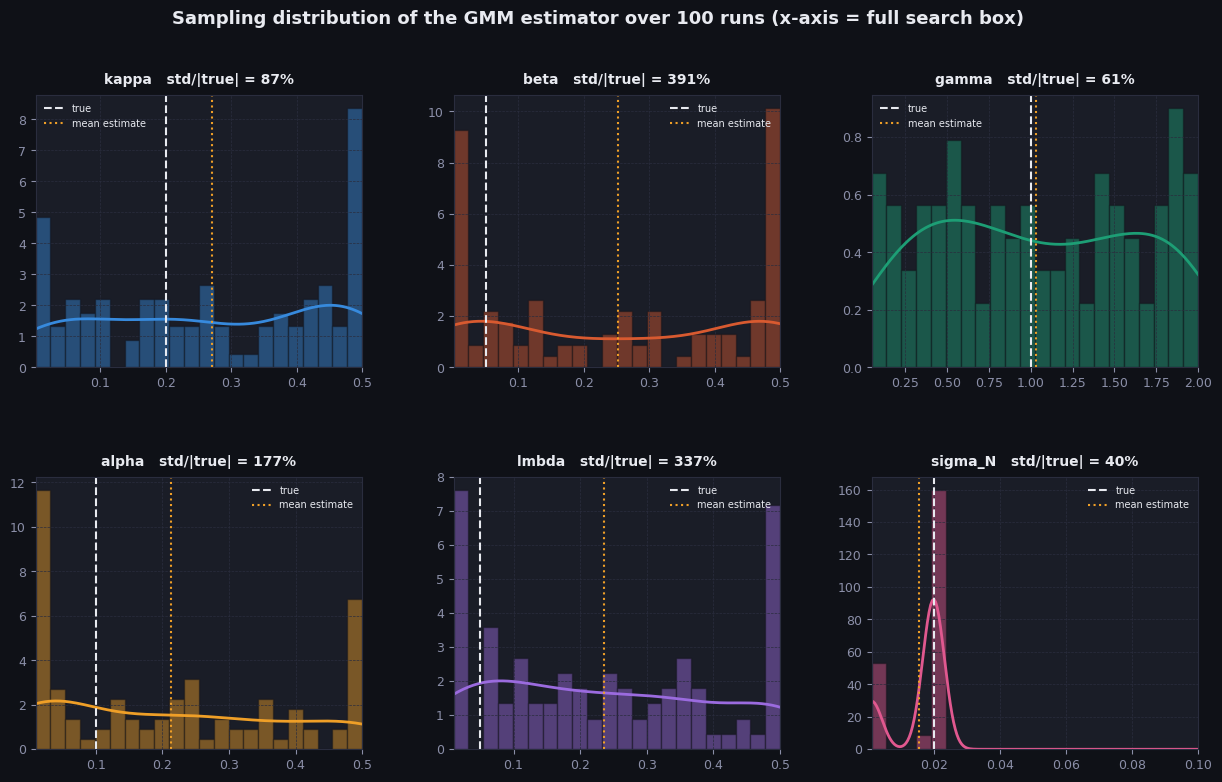

In [13]:
fig = plt.figure(figsize=(15, 8.5)); fig.patch.set_facecolor(DARK)
gs_ = gridspec.GridSpec(2, 3, figure=fig, hspace=0.4, wspace=0.28)
pcolors = [BLUE, CORAL, TEAL, AMBER, VIOLET, "#E0588F"]
for j, nm in enumerate(PARAM_NAMES):
    ax = fig.add_subplot(gs_[j // 3, j % 3]); data = estimates[:, j]
    ax.hist(data, bins=22, range=(gmm.LO[j], gmm.HI[j]), color=pcolors[j], alpha=0.45,
            density=True, edgecolor=DARK)
    if data.std() > 1e-9:
        xs = np.linspace(gmm.LO[j], gmm.HI[j], 200); ax.plot(xs, gaussian_kde(data)(xs), color=pcolors[j], lw=2)
    ax.axvline(TRUE[j], color=WHITE, ls="--", lw=1.5, label="true")
    ax.axvline(data.mean(), color=AMBER, ls=":", lw=1.5, label="mean estimate")
    ax.set_xlim(gmm.LO[j], gmm.HI[j])
    style_ax(ax, f"{nm}   std/|true| = {rel_std[nm]:.0%}")
    ax.legend(fontsize=7, framealpha=0, labelcolor=WHITE)
fig.suptitle(f"Sampling distribution of the GMM estimator over {N_MC} runs (x-axis = full search box)",
             color=WHITE, fontsize=13, fontweight="bold", y=0.98)
save(fig, "01_sloppiness_densities.png"); plt.show()

### Reading the 100 runs

**Only $\sigma_N$ is identified.** In 74% of the runs it lands within ±10% of the true value; the remaining 24% are optimiser failures stuck at the lower bound, which is what drags the mean down to 0.015.

**The five behavioural parameters are not identified at all.** For $\kappa, \beta, \gamma, \alpha, \lambda$ the 5–95% range of the estimates covers 96–100% of the search box, and the histograms are close to uniform with spikes at the bounds. The **mean estimates sit at the centre of the box** (κ 0.27 vs centre 0.25, β 0.25 vs 0.25, γ 1.03 vs 1.025, α 0.21 vs 0.255, λ 0.24 vs 0.255), not at the true values.

This corrects a conclusion of the original team notebook, which proposed the *average of the 100 estimates* as the final estimator on the basis of the law of large numbers. The average converges to $\mathbb E[\hat\xi]$, not to $\xi^\*$: when $\hat\xi$ is essentially uniform on the box, $\mathbb E[\hat\xi]$ is the centre of the box and averaging only produces a precise estimate of the prior. Repetition is the right tool to **diagnose** sloppiness, not to remove it.

The diagnosis matches §3: the behavioural terms are two orders of magnitude below the noise, so six static moments of a 1,500-step path carry almost no information about them.

## 8 · Loss landscape: $W = I$ versus $W = \hat V^{-1}$

A 2-D slice of $D_W$ in the $(\lambda, \beta)$ plane, other parameters fixed at their true values, evaluated on a 25 × 25 grid.

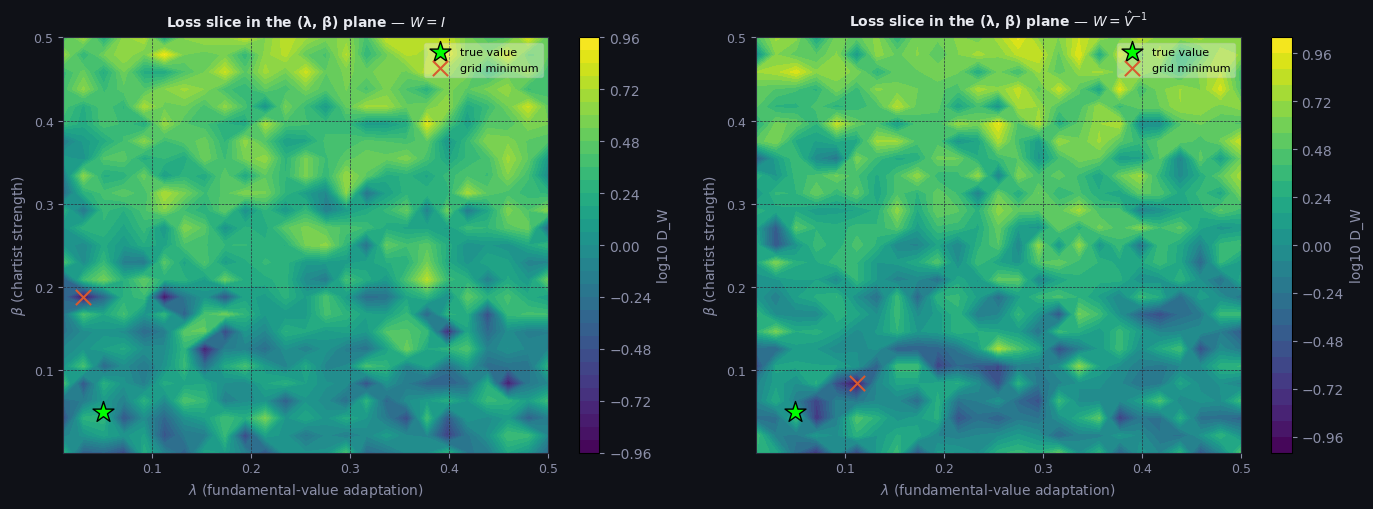

In [14]:
np.random.seed(4)
n_points = 25
lam_vals = np.linspace(0.01, 0.5, n_points); beta_vals = np.linspace(0.001, 0.5, n_points)
L, B = np.meshgrid(lam_vals, beta_vals)
Z_unit = np.zeros_like(L); Z_opt = np.zeros_like(L)
for i in range(n_points):
    for j in range(n_points):
        x_eval = [TRUE[0], B[i, j], TRUE[2], TRUE[3], L[i, j], TRUE[5]]
        Z_unit[i, j] = distance(x_eval, np.eye(6)); Z_opt[i, j] = distance(x_eval, W_opt)

fig, axes = new_fig(1, 2, figsize=(14, 5.2))
for ax, Z, title in [(axes[0], Z_unit, "$W = I$"), (axes[1], Z_opt, r"$W = \hat V^{-1}$")]:
    cs = ax.contourf(L, B, np.log10(Z + 1e-3), levels=30, cmap="viridis")
    ax.scatter(TRUE[4], TRUE[1], marker="*", s=250, color="lime", edgecolor="k", zorder=5, label="true value")
    k = np.unravel_index(np.argmin(Z), Z.shape)
    ax.scatter(L[k], B[k], marker="x", s=120, color=CORAL, zorder=5, label="grid minimum")
    cb = fig.colorbar(cs, ax=ax); cb.set_label("log10 D_W", color=LGRAY); cb.ax.tick_params(colors=LGRAY)
    ax.set_xlabel(r"$\lambda$ (fundamental-value adaptation)"); ax.set_ylabel(r"$\beta$ (chartist strength)")
    style_ax(ax, f"Loss slice in the (λ, β) plane — {title}"); ax.legend(fontsize=8, framealpha=0.3)
plt.tight_layout(); save(fig, "01_loss_landscape.png"); plt.show()

Both slices look like **noise without a valley**. Neither the unit nor the optimal weighting produces a basin around the true value (green star), and the grid minimum (red cross) falls at an arbitrary point that changes with the random seed. Optimal weighting cannot create information the moments do not contain; at most it rescales it.

## 9 · Surrogate models and surrogate-assisted ABC

The landscape is noisy and each evaluation costs simulations, so a natural idea is to learn a smooth **surrogate** of $D_W$ with a regressor and work on it instead.

### 9.1 · Random-forest surrogate on the $(\lambda, \beta)$ slice
600 true evaluations at random points, a random forest fitted on them, then predicted on a dense grid.

5-fold CV R² of the surrogate on log-loss: -0.02
Surrogate minimum: lambda = 0.300, beta = 0.036   (true: lambda = 0.05, beta = 0.05)


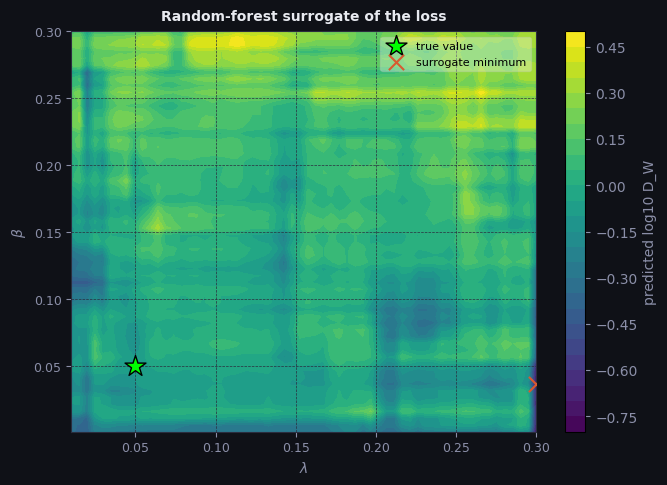

In [15]:
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score

np.random.seed(42)
N_samples = 600
tr_lam = np.random.uniform(0.01, 0.3, N_samples); tr_beta = np.random.uniform(0.001, 0.3, N_samples)
X_rf = np.column_stack((tr_lam, tr_beta))
y_rf = np.array([distance([TRUE[0], b, TRUE[2], TRUE[3], l, TRUE[5]], np.eye(6))
                 for l, b in X_rf])
rf = RandomForestRegressor(n_estimators=100, max_depth=10, random_state=42)
print(f"5-fold CV R² of the surrogate on log-loss: "
      f"{cross_val_score(rf, X_rf, np.log(y_rf + 1e-3), cv=5, scoring='r2').mean():.2f}")
rf.fit(X_rf, np.log(y_rf + 1e-3))

g = 60
Lg, Bg = np.meshgrid(np.linspace(0.01, 0.3, g), np.linspace(0.001, 0.3, g))
Zg = rf.predict(np.column_stack((Lg.ravel(), Bg.ravel()))).reshape(Lg.shape)
k = np.unravel_index(np.argmin(Zg), Zg.shape)
print(f"Surrogate minimum: lambda = {Lg[k]:.3f}, beta = {Bg[k]:.3f}   (true: lambda = {TRUE[4]}, beta = {TRUE[1]})")

fig, ax = new_fig(figsize=(7.5, 5.2))
cs = ax.contourf(Lg, Bg, Zg / np.log(10), levels=30, cmap="viridis")
ax.scatter(TRUE[4], TRUE[1], marker="*", s=250, color="lime", edgecolor="k", label="true value", zorder=5)
ax.scatter(Lg[k], Bg[k], marker="x", s=120, color=CORAL, label="surrogate minimum", zorder=5)
cb = fig.colorbar(cs, ax=ax); cb.set_label("predicted log10 D_W", color=LGRAY); cb.ax.tick_params(colors=LGRAY)
ax.set_xlabel(r"$\lambda$"); ax.set_ylabel(r"$\beta$"); ax.legend(fontsize=8, framealpha=0.3)
style_ax(ax, "Random-forest surrogate of the loss"); plt.show()

### 9.2 · Surrogate-assisted Approximate Bayesian Computation (S-ABC), all 6 parameters

1. 800 points from a scrambled **Sobol** design over the 6-D box, each evaluated with the true $D_I$;
2. **XGBoost** fitted on the (capped) log-loss;
3. 100,000 prior draws scored by the surrogate in milliseconds; the best 1% are kept as an approximate posterior.

In [16]:
import xgboost as xgb
from scipy.stats import qmc

np.random.seed(5)
bounds_abc = np.array([[0.0, 0.5], [0.0, 0.3], [0.1, 3.0], [0.0, 0.5], [0.0, 0.3], [0.001, 0.1]])
N_TRAIN, N_ABC, ACCEPT = 800, 100_000, 0.01

X_s = bounds_abc[:, 0] + qmc.Sobol(d=6, scramble=True, seed=42).random(N_TRAIN) * np.ptp(bounds_abc, axis=1)
y_s = np.array([distance(x, np.eye(6)) for x in X_s])
ok = np.isfinite(y_s); X_s, y_s = X_s[ok], y_s[ok]
y_log = np.log(np.minimum(y_s, np.percentile(y_s, 90)) + 1e-9)
surrogate_xgb = xgb.XGBRegressor(n_estimators=300, max_depth=5, learning_rate=0.05, random_state=42)
print(f"{ok.sum()} valid simulations | 5-fold CV R² of XGBoost on log-loss: "
      f"{cross_val_score(surrogate_xgb, X_s, y_log, cv=5, scoring='r2').mean():.2f}")
surrogate_xgb.fit(X_s, y_log)

prior = np.random.uniform(bounds_abc[:, 0], bounds_abc[:, 1], size=(N_ABC, 6))
pred = surrogate_xgb.predict(prior)
posterior = prior[np.argsort(pred)[: int(N_ABC * ACCEPT)]]
abc_mean, abc_map = posterior.mean(0), posterior[0]

print(f"\n{'param':<9}{'true':>8}{'post. mean':>12}{'post. std':>11}{'MAP':>8}{'prior std':>11}")
for j, nm in enumerate(PARAM_NAMES):
    print(f"{nm:<9}{TRUE[j]:>8.3f}{abc_mean[j]:>12.3f}{posterior[:, j].std():>11.3f}{abc_map[j]:>8.3f}"
          f"{np.ptp(bounds_abc[j]) / np.sqrt(12):>11.3f}")

796 valid simulations | 5-fold CV R² of XGBoost on log-loss: 0.99



param        true  post. mean  post. std     MAP  prior std
kappa       0.200       0.252      0.148   0.349      0.144
beta        0.050       0.140      0.086   0.006      0.087
gamma       1.000       1.358      0.800   0.731      0.837
alpha       0.100       0.232      0.142   0.021      0.144
lmbda       0.050       0.169      0.082   0.272      0.087
sigma_N     0.020       0.020      0.000   0.020      0.029


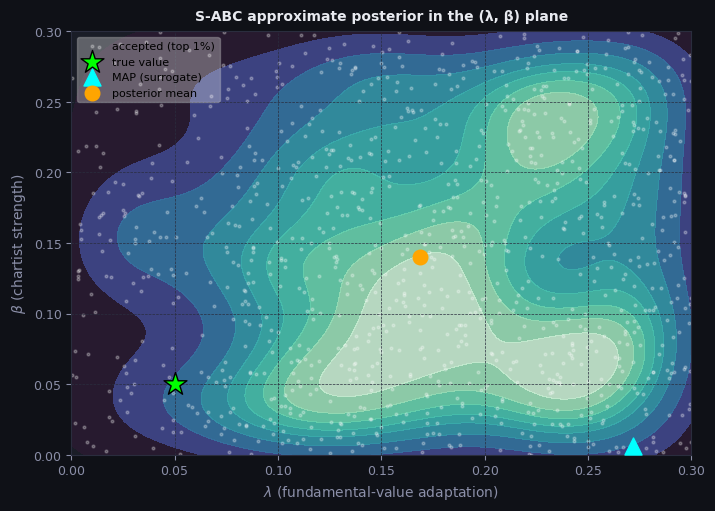

In [17]:
import seaborn as sns
fig, ax = new_fig(figsize=(8, 5.5))
sns.kdeplot(x=posterior[:, 4], y=posterior[:, 1], cmap="mako", fill=True, ax=ax, alpha=0.9)
ax.scatter(posterior[:, 4], posterior[:, 1], color="white", s=4, alpha=0.25, label="accepted (top 1%)")
ax.scatter(TRUE[4], TRUE[1], marker="*", color="lime", s=300, edgecolor="k", label="true value", zorder=5)
ax.scatter(abc_map[4], abc_map[1], marker="^", color="cyan", s=150, label="MAP (surrogate)", zorder=5)
ax.scatter(abc_mean[4], abc_mean[1], marker="o", color="orange", s=110, label="posterior mean", zorder=5)
ax.set_xlim(*bounds_abc[4]); ax.set_ylim(*bounds_abc[1])
ax.set_xlabel(r"$\lambda$ (fundamental-value adaptation)"); ax.set_ylabel(r"$\beta$ (chartist strength)")
style_ax(ax, "S-ABC approximate posterior in the (λ, β) plane"); ax.legend(fontsize=8, framealpha=0.3)
save(fig, "01_sabc_posterior.png"); plt.show()

### Reading the surrogate results

The two surrogates tell the same story as the 100 GMM runs, from a different angle:

- **On the $(\lambda, \beta)$ slice the random forest has a cross-validated R² of about 0**: once $\sigma_N$ is fixed there is no learnable structure, only simulation noise. Its "minimum" (λ = 0.30, β = 0.04) is an artefact of where the noise happened to fall.
- **In 6-D, XGBoost reaches R² ≈ 0.99**, but almost all of that is $\sigma_N$, which drives the variance moment. The S-ABC posterior is sharp for $\sigma_N$ (posterior std ≈ 0.000 vs prior std 0.029) and **equal to the prior for every other parameter** (posterior std 0.148 vs prior 0.144 for κ, 0.086 vs 0.087 for β, 0.142 vs 0.144 for α...). The MAP is a single draw from that flat region and should not be read as an estimate.

Surrogates are a good way to make an expensive simulator cheap, but they inherit the information content of the moments. They cannot fix an identification problem.

## 10 · Why fitting the deterministic trajectory fails

A different team approach (initially called "PINN-like") skips moments altogether: fit the **noise-free** model $p^{\det}_t(\theta)$ to an observed path by minimising the MSE between observed and model returns, with `scipy.optimize` and with a small neural network that outputs $\theta$ and is trained through a differentiable simulator. To reduce noise, the target was the **average of 1,000 simulated paths**.

The cells below show why this cannot work for this model, and why the MSE came out the same for every method and every parameter vector.

In [18]:
@njit(cache=True)
def chiarella_det(T, kappa, beta, gamma, alpha, lam, p1):
    # Noise-free model, started from a small initial kick p1
    v = np.zeros(T); m = np.zeros(T); p = np.zeros(T + 1); p[1] = p1
    for t in range(1, T):
        v[t] = (1 - lam) * v[t-1] + lam * p[t]
        m[t] = (1 - alpha) * m[t-1] + alpha * (p[t] - p[t-1])
        p[t+1] = p[t] + kappa * ((v[t]-p[t])**3 - (v[t-1]-p[t-1])**3) \
                      + beta * (np.tanh(gamma*m[t]) - np.tanh(gamma*m[t-1]))
    return p

# Data-generating parameters of the original experiment
kappa_, beta_, gamma_, sigma_, alpha_, lam_ = 0.02, 0.30, 2.0, 0.005, 0.05, 0.02
T_, RUNS = 1000, 1000
rng = np.random.default_rng(0)
paths = np.array([chiarella_model(rng.normal(0, 1, T_ + 1), kappa_, beta_, gamma_, alpha_, lam_, sigma_)[0]
                  for _ in range(RUNS)])
mean_path = paths.mean(0); se = paths.std(0) / np.sqrt(RUNS)
inside = np.mean(np.abs(mean_path) <= 2 * se)
print(f"Average of {RUNS} paths: max |E[p_t]| = {np.abs(mean_path).max():.2e}, "
      f"typical single-path |p_t| = {np.abs(paths[:, -1]).mean():.2e}")
print(f"Share of dates where the average path is within ±2 standard errors of 0: {inside:.0%}")

Average of 1000 paths: max |E[p_t]| = 5.14e-03, typical single-path |p_t| = 1.29e-01
Share of dates where the average path is within ±2 standard errors of 0: 100%


**Symmetry argument.** The cubic and $\tanh$ terms are odd functions and the shocks are symmetric. With a zero initial state, $(p_t)$ and $(-p_t)$ have the same distribution, so $\mathbb E[p_t] = 0$ for **every** $t$ and **every** parameter vector. Averaging paths therefore removes the parameters' signature together with the noise: what is left is Monte-Carlo error of size $\sigma\sqrt{t/N}$.

A deterministic fit then has nothing to explain. We check this by fitting the noise-free model with several optimisers, on one path and on the 1,000-path average, and comparing the MSE with the MSE of predicting **zero returns**:

In [19]:
def fit_report(prices, label):
    rets = np.diff(prices)
    obj = lambda th: np.mean((rets - np.diff(chiarella_det(T_, *th, prices[1]))) ** 2)
    bnds = [(1e-2, 5.0), (1e-2, 5.0), (1e-2, 25.0), (1e-2, 1.0), (1e-3, 1.0)]
    x0 = [0.2, 3.0, 10.0, 0.05, 0.1]
    base = np.mean(rets ** 2)
    print(f"--- {label}:  MSE of predicting r_t = 0 is {base:.4e}")
    for mth in ["Nelder-Mead", "Powell", "L-BFGS-B"]:
        with np.errstate(all="ignore"):
            res = minimize(obj, x0, method=mth, bounds=bnds)
        print(f"  {mth:<12} MSE = {res.fun:.4e}  ->  share of variance explained = {1 - res.fun / base:+.2%}"
              f"   theta = {np.round(res.x, 3)}")

fit_report(paths[0], "single simulated path")
fit_report(mean_path, f"average of {RUNS} paths")

--- single simulated path:  MSE of predicting r_t = 0 is 2.3942e-05
  Nelder-Mead  MSE = 2.3942e-05  ->  share of variance explained = +0.00%   theta = [ 0.2   3.   10.    0.05  0.1 ]
  Powell       MSE = 2.3942e-05  ->  share of variance explained = +0.00%   theta = [ 5.  5. 25.  1.  1.]
  L-BFGS-B     MSE = 2.3942e-05  ->  share of variance explained = +0.00%   theta = [ 0.2   3.   10.    0.05  0.1 ]
--- average of 1000 paths:  MSE of predicting r_t = 0 is 2.6806e-08
  Nelder-Mead  MSE = 2.6806e-08  ->  share of variance explained = +0.00%   theta = [ 0.2   3.   10.    0.05  0.1 ]
  Powell       MSE = 2.6806e-08  ->  share of variance explained = +0.00%   theta = [ 5.  5. 25.  1.  1.]
  L-BFGS-B     MSE = 2.6806e-08  ->  share of variance explained = +0.00%   theta = [ 0.2   3.   10.    0.05  0.1 ]


Every optimiser explains **0.00% of the variance**, on the single path as well as on the average, and most of them do not move from the initial guess: the objective is flat because the deterministic model, started at the observed $p_1$, stays at its steady state whatever $\theta$. On the averaged target, the MSE equals the MSE of predicting zero returns (2.68e-8), which is exactly the number observed in the original experiment for every method. It is the variance of the Monte-Carlo residual, not a fit quality.

**Lesson.** For a stochastic model, the calibration target has to be a quantity whose expectation depends on the parameters (moments, likelihood, or filtered states), never the expected path when the model is symmetric. The neural "PINN-like" variant optimises the same objective through a differentiable simulator and therefore hits the same wall.

## 11 · Conclusions

| Step | Result |
|---|---|
| Simulator | Numba-compiled modified Chiarella model: 1,000 paths of 1,500 steps in ~0.05 s |
| Regimes | Visually distinct paths, but **indistinguishable return moments**: noise is 50–180× larger than the behavioural terms |
| GMM distance | Noisy (CV ≈ 60% at a fixed point); common random numbers make it deterministic |
| Optimisers | Finite-difference gradients fail; COBYLA/COBYQA always "converge", but differential evolution reaches the lowest losses. The `success` flag is a misleading selection criterion |
| 100 re-estimations | **σ_N identified** (74% of runs within ±10%); **κ, β, γ, α, λ not identified**: estimates spread over the whole box, their mean is the centre of the box |
| Surrogates / S-ABC | Excellent fit (R² 0.99) driven by σ_N alone; posterior = prior for the five behavioural parameters |
| Trajectory fitting | Structurally impossible: by symmetry the expected path is zero for every parameter vector |

**Main takeaway.** The calibration machinery works (σ_N is recovered and every tool agrees), and it is precisely because it works that it exposes a property of the *model at these parameter values*: the behavioural mechanism is buried under the noise, so no estimator can recover it from these six moments. Checking identifiability on synthetic data **before** touching real data is what makes that visible.

**What I would do next**
1. **Choose informative moments**: multi-lag ACFs of $r$ and $|r|$, variance ratios at several horizons, cross-moments between $r_t$ and past cumulative returns; the trend and mean-reversion mechanisms live in these dynamic statistics, not in static ones.
2. **Calibrate in a regime where agents matter**: larger mispricings or a stronger chartist feedback, and report identification as a function of the signal-to-noise ratio of the behavioural terms.
3. **Use common random numbers by default** and select optimisers on re-evaluated loss; with a deterministic objective, gradient-free local methods become competitive again.
4. **Move to likelihood-based inference** (particle filter on the latent $(p_t, m_t, v_t)$, as attempted in notebook 03) to use the whole path instead of six summary statistics.